# Chapitre 11 - Cours 2 : les courtiers fondés sur un journal partitionné

Un courtier de style AMQP/JMS hérite d'une mentalité de messagerie **transitoire** :
même s'il écrit sur disque, il efface le message dès qu'il est acquitté. Recevoir un
message est donc une opération **destructive** : on ne peut pas relancer un consommateur
pour obtenir le même résultat, et un nouveau consommateur ne voit que les messages
arrivés après son inscription. Les bases de données et les fichiers font l'inverse :
ce qui est écrit reste, et un nouveau client peut lire le passé. Les courtiers à
**journal** (log-based message brokers) combinent les deux : stockage durable d'une base,
notification à faible latence d'une messagerie.

Ce notebook couvre la section *Partitioned Logs* : *Using logs for message
storage*, *Logs compared to traditional messaging*, *Consumer offsets*, *Disk space
usage*, *When consumers cannot keep up with producers*, *Replaying old messages*. Les
exemples s'appuient sur la classe `PartitionedLog` de
[`ddia/streams.py`](../../ddia/streams.py), un journal partitionné en mémoire qui reprend
les choix de Kafka (y compris son partitionneur murmur2) ; le lab Kafka du chapitre
reproduit les mêmes expériences sur un vrai courtier.

**Plan.**

1. Un journal pour stocker les messages.
2. Journal contre messagerie traditionnelle : groupes de consommateurs et blocage en tête de file.
3. Les offsets des consommateurs.
4. Espace disque, tampon circulaire et consommateurs lents.
5. Rejouer les anciens messages.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import streams as st
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 2)
rng = np.random.default_rng(0)

## 1. Un journal pour stocker les messages (section *Using logs for message storage*)

Un **journal** est une suite d'enregistrements en **ajout seul** (append-only) sur disque :
on l'a rencontré pour les moteurs de stockage et les journaux d'écriture anticipée
(chapitre 3), pour la réplication (chapitre 5) et comme forme
de consensus (chapitre 9). La même structure fait un courtier : le
producteur **ajoute** le message à la fin du journal, le consommateur le **lit
séquentiellement** et, arrivé au bout, attend d'être notifié d'un nouvel ajout, exactement
comme `tail -f` sur un fichier.

Pour dépasser le débit d'un seul disque, le journal est **partitionné** (au sens du chapitre 6 ; Kafka parle de
*partitions*) : chaque partition est un journal indépendant, hébergé sur sa machine, et un
**sujet** est un groupe de partitions qui portent le même type de messages. Dans chaque
partition, le courtier attribue à chaque message un numéro croissant, son **offset**. Les
messages d'une partition sont donc **totalement ordonnés** ; il n'y a **aucune garantie
d'ordre entre partitions**.

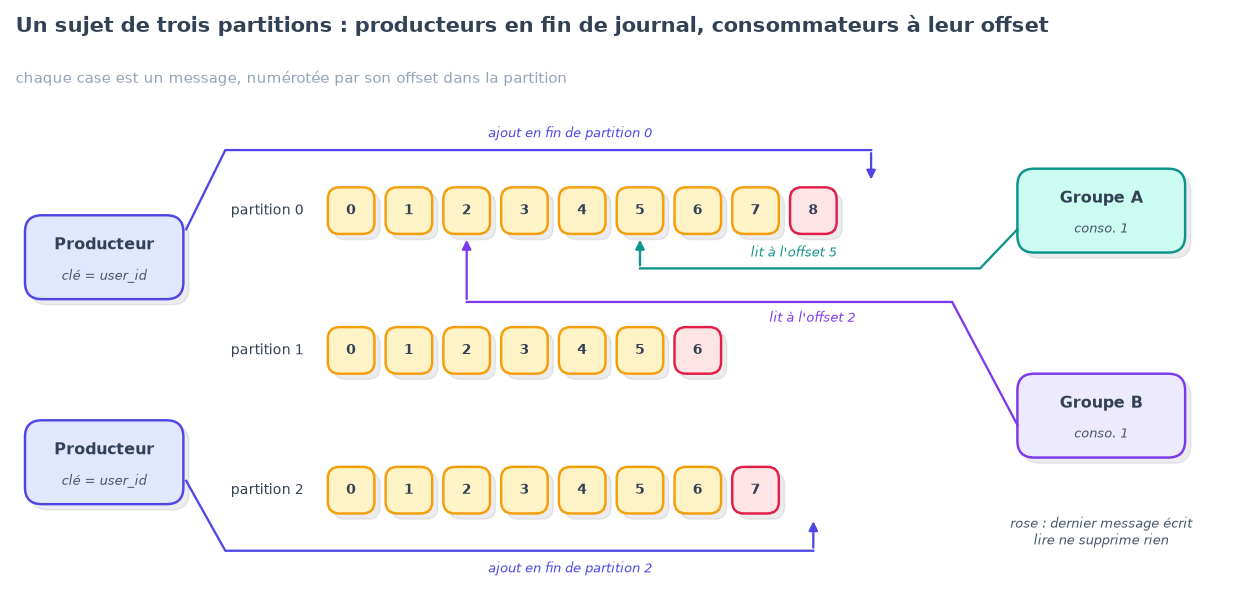

In [2]:
d = Diagram(13, 5.4, title="Un sujet de trois partitions : producteurs en fin de journal, consommateurs à leur offset",
            subtitle="chaque case est un message, numérotée par son offset dans la partition")
d.box("p1", 1.0, 3.7, "Producteur", sub="clé = user_id", color=INDIGO, w=1.7)
d.box("p2", 1.0, 1.5, "Producteur", sub="clé = user_id", color=INDIGO, w=1.7)
longueurs = [9, 7, 8]
ys = [4.2, 2.7, 1.2]
for p, (n, y) in enumerate(zip(longueurs, ys)):
    d.note(2.75, y, f"partition {p}", fontsize=9, style="normal", color=SLATE)
    for o in range(n):
        d.box(f"c{p}_{o}", 3.65 + 0.62 * o, y, str(o), color=AMBER if o < n - 1 else ROSE, w=0.5, h=0.5,
              fontsize=9)
d.box("ca", 11.7, 4.2, "Groupe A", sub="conso. 1", color=TEAL, w=1.8)
d.box("cb", 11.7, 2.0, "Groupe B", sub="conso. 1", color=VIOLET, w=1.8)
x_of = lambda o: 3.65 + 0.62 * o
d.line([(1.88, 4.0), (2.3, 4.85), (x_of(9), 4.85), (x_of(9), 4.5)], color=INDIGO, style="solid", lw=1.5)
d.line([(1.88, 1.3), (2.3, 0.55), (x_of(8), 0.55), (x_of(8), 0.9)], color=INDIGO, style="solid", lw=1.5)
d.note(6.0, 5.03, "ajout en fin de partition 0", color=INDIGO, fontsize=8.5)
d.note(6.0, 0.36, "ajout en fin de partition 2", color=INDIGO, fontsize=8.5)
d.line([(10.8, 4.0), (10.4, 3.58), (x_of(5), 3.58), (x_of(5), 3.92)], color=TEAL, style="solid", lw=1.5)
d.line([(10.8, 1.9), (10.1, 3.22), (x_of(2), 3.22), (x_of(2), 3.92)], color=VIOLET, style="solid", lw=1.5)
d.note(8.4, 3.75, "lit à l'offset 5", color=TEAL, fontsize=8.5)
d.note(8.6, 3.05, "lit à l'offset 2", color=VIOLET, fontsize=8.5)
d.note(11.7, 0.75, "rose : dernier message écrit\nlire ne supprime rien", fontsize=8.5)
d.show()

Les deux groupes lisent la même partition 0 à des positions différentes, sans se gêner :
lire ne modifie pas le journal. Construisons un tel sujet et vérifions les propriétés
annoncées : offsets contigus dans chaque partition, et **tous les messages d'une même
clé dans la même partition, dans l'ordre**. C'est ce qui permet à une application
d'exiger que les événements d'un utilisateur restent ordonnés : il suffit de prendre
l'identifiant de l'utilisateur comme clé de partitionnement.

offsets contigus : True ; ordre préservé par clé : True
partition de user-42 : 4 (murmur2, identique à Kafka)


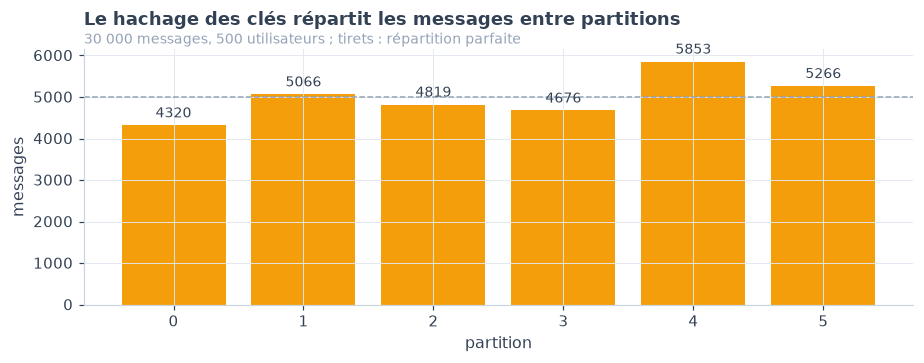

In [3]:
log = st.PartitionedLog(n_partitions=6, segment_size=1000)
users = [f"user-{i}" for i in range(500)]
for i in range(30_000):
    u = users[int(rng.integers(0, 500))]
    log.append(u, {"user": u, "seq": i})

par_part = [log.size(p) for p in range(6)]
ok_offsets = all([r.offset for r in log.read(p, 0)] == list(range(log.size(p))) for p in range(6))
ok_ordre = True
for u in users[:50]:
    p = log.partition_for(u)
    seqs = [r.value["seq"] for r in log.read(p, 0) if r.key == u]
    ok_ordre &= seqs == sorted(seqs)
print(f"offsets contigus : {ok_offsets} ; ordre préservé par clé : {ok_ordre}")
print("partition de user-42 :", log.partition_for("user-42"), "(murmur2, identique à Kafka)")

fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.bar(range(6), par_part, color=AMBER)
annotate_bars(ax, "{:.0f}")
ax.axhline(30_000 / 6, color=GRAY, ls="--", lw=1)
ax.set_xlabel("partition"); ax.set_ylabel("messages")
ax.set_title("Le hachage des clés répartit les messages entre partitions")
subtitle(ax, "30 000 messages, 500 utilisateurs ; tirets : répartition parfaite")
plt.tight_layout(); plt.show()

La répartition est proche de l'uniforme parce que les 500 clés sont également actives ;
avec une clé très active (un compte célèbre), sa partition serait surchargée : c'est le
problème des clés chaudes du chapitre 6 (voir l'exercice 11.2).
Kafka et Amazon Kinesis Streams fonctionnent ainsi : bien qu'ils écrivent tout sur disque,
ils atteignent des millions de messages par seconde en partitionnant sur plusieurs
machines, et tolèrent les pannes en répliquant les partitions.

> **À retenir.** Un courtier à journal ajoute les messages en fin de partition et les
> numérote par un offset ; les consommateurs lisent séquentiellement. L'ordre est total
> dans une partition et inexistant entre partitions : ce qui doit rester ordonné doit
> partager une clé.

## 2. Journal contre messagerie traditionnelle (section *Logs compared to traditional messaging*)

La **diffusion** est gratuite : plusieurs consommateurs lisent le journal chacun à son
rythme. Pour la **répartition de charge** dans un groupe, le courtier n'affecte pas des
messages individuels mais des **partitions entières** à chaque membre, qui les lit
séquentiellement dans un seul fil d'exécution.

In [4]:
for membres in (["c1", "c2"], ["c1", "c2", "c3", "c4"], [f"c{i}" for i in range(1, 9)]):
    a = st.range_assign(6, membres)
    print(f"{len(membres)} membres :", {m: ps for m, ps in a.items()})

2 membres : {'c1': [0, 1, 2], 'c2': [3, 4, 5]}
4 membres : {'c1': [0, 1], 'c2': [2, 3], 'c3': [4], 'c4': [5]}
8 membres : {'c1': [0], 'c2': [1], 'c3': [2], 'c4': [3], 'c5': [4], 'c6': [5], 'c7': [], 'c8': []}


Cette répartition à gros grain a deux inconvénients :

- le nombre de consommateurs utiles d'un groupe est **plafonné par le nombre de
  partitions** : avec 6 partitions, les membres 7 et 8 restent inactifs ;
- un message lent à traiter **bloque tous les suivants de sa partition** (blocage en tête
  de file, head-of-line blocking, chapitre 1).

Simulons ce second effet : 20 000 messages arrivent à 80 % de la capacité de 8
consommateurs ; le temps de traitement est le plus souvent court, mais 0,5 % des messages
prennent 100 fois plus longtemps. On compare une file partagée (style AMQP, le premier
consommateur libre prend le message suivant) à 8 partitions servies chacune dans l'ordre.

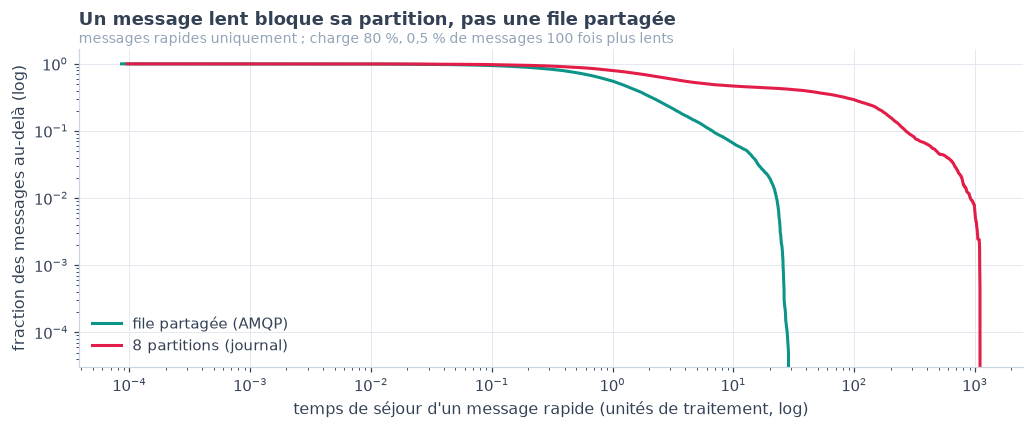

,p50,p90,p99,p99.9
file partagée (AMQP),1.17,6.71,22.73,25.76
8 partitions (journal),6.16,267.19,916.44,1092.07


In [5]:
n, k = 20_000, 8
serv = rng.exponential(1.0, n)
lents = rng.random(n) < 0.005
serv[lents] *= 100
arr = np.cumsum(rng.exponential(serv.mean() / (0.8 * k), n))
cles = rng.integers(0, 10_000, n)
lat = {"file partagée (AMQP)": st.hol_latencies(arr, serv, k, "shared"),
       "8 partitions (journal)": st.hol_latencies(arr, serv, k, "partitioned", keys=cles)}
fig, ax = plt.subplots(figsize=(9.5, 4))
for (nom, x), c in zip(lat.items(), [TEAL, ROSE]):
    xs = np.sort(x[~lents])
    ax.plot(xs, 1 - np.arange(1, xs.size + 1) / xs.size, color=c, label=nom)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("temps de séjour d'un message rapide (unités de traitement, log)")
ax.set_ylabel("fraction des messages au-delà (log)")
ax.set_title("Un message lent bloque sa partition, pas une file partagée")
subtitle(ax, "messages rapides uniquement ; charge 80 %, 0,5 % de messages 100 fois plus lents")
ax.legend()
plt.tight_layout(); plt.show()
pd.DataFrame({nom: {f"p{q}": np.percentile(x[~lents], q) for q in (50, 90, 99, 99.9)}
              for nom, x in lat.items()}).T

Pour les messages **rapides**, le p99 passe d'une vingtaine d'unités avec la file
partagée à près d'un millier avec les partitions, et même la médiane est multipliée par
cinq : un message coincé derrière un message lent de sa partition attend, même si les
sept autres consommateurs sont libres. (S'y ajoute un léger déséquilibre de charge entre
partitions, puisque les clés sont tirées au hasard.) D'où la règle
pratique du livre :

- messages coûteux, à paralléliser message par message, ordre peu important : courtier
  de style **JMS/AMQP** ;
- débit élevé, messages rapides à traiter, **ordre important** : courtier à **journal**.

Partager une partition entre deux consommateurs est possible (l'un traite les offsets
pairs, l'autre les impairs) ou par un pool de fils, mais cela complique la gestion des
offsets ; mieux vaut un seul fil par partition et augmenter le nombre de partitions.


> **À retenir.** Dans un journal, la répartition de charge se fait par partition :
> parallélisme plafonné par le nombre de partitions, ordre garanti par partition, mais un
> message lent bloque ses successeurs.